In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from models.NeuralNet_AnomalyDetection import NeuralNet_AnomalyDetection


class Resample(layers.Layer):

    def call(self, inputs):
        mean, log_var = inputs
        e = tf.keras.backend.random_normal(shape=(tf.shape(mean)[0], tf.shape(mean)[1]))
        return mean + tf.exp(0.5 * log_var) * e



class VAE(NeuralNet_AnomalyDetection):
    def __init__(self, input_dim, latent_dim):
        super(VAE, self).__init__()

        self.latent_dim = latent_dim
        self.input_dim = input_dim

        encoder_inputs = keras.Input(shape=(self.input_dim,))
        x = layers.Dense(16, activation="relu")(encoder_inputs)
        z_mean = layers.Dense(self.latent_dim, name="z_mean")(x)
        z_log_var = layers.Dense(self.latent_dim, name="z_log_var")(x)
        z = Resample()([z_mean, z_log_var])
        self.encoder = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")


        latent_inputs = keras.Input(shape=(self.latent_dim,))
        x = layers.Dense(16, activation="relu")(latent_inputs)
        x = layers.Dense(30, activation="relu")(x)
        decoder_outputs = layers.Dense(self.input_dim, activation="sigmoid")(x)
        self.decoder = keras.Model(latent_inputs, decoder_outputs, name="decoder")

    
    def call(self, inp):
        _, _, z = self.encoder(inp)
        return self.decoder(z)
    
    def vae_loss(self, data):
        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)
        reconstruction_loss = tf.reduce_mean(keras.losses.binary_crossentropy(data, reconstruction))

        kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
        kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
        return reconstruction_loss + kl_loss

    def train_step(self, data):
        
        with tf.GradientTape() as tape:
            total_loss = self.vae_loss(data)
        
        #apply the gradient to the optimizer to improve the model
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        return total_loss


    def train(self, data, epochs, batch_size, validation_split=0.2):
                
        # splitting the data into training and validation set
        x_train, x_val = train_test_split(data, test_size=validation_split)

        # for each epoch...
        epoch_loss = []
        for epoch in range(epochs):

            for x in range(0, len(x_train), batch_size):
                # the data is splitted into batches
                # of size batch data and converted to a tensor
                x_inp = tf.convert_to_tensor(
                    x_train[x: x + batch_size], dtype=tf.float32)
                # the loss for this batch of data is computed and the network updated
                loss_value = self.train_step(x_inp)


            # the validation set is not used for training
            # at every epoch it will be computed the method loss on it
            x_val = tf.convert_to_tensor(x_val)
            val_loss = self.vae_loss(x_val)
            print("Epoch: {}, Train Loss: {}, Val Loss: {}".format(
                epoch, tf.reduce_mean(loss_value), tf.reduce_mean(val_loss)))

            # training loss and validation loss are concated in the epoch's loss
            epoch_loss.append(
                [tf.reduce_mean(loss_value),  tf.reduce_mean(val_loss)])

        return epoch_loss

input_data = np.random.random((100, 30))  # Example input data with shape (None, 30)


df = pd.read_csv('SimData.csv')


target_feature = "isghost"
# instantiate two more datasets one to contain the normal data
# and the other to hold the anomalous instances
normal_data = df[df[target_feature] == 0].drop(columns=target_feature)
anomalous_data = df[df[target_feature] == 1].drop(columns=target_feature)

# also instantiate a dataframe to carry all the features
# and a second one to instead contain the target variable
features = df.drop([target_feature], axis=1)
label = df[target_feature]

# the stratify parameter here is set to be "isghost" meaning that the
# proportions of ghost and normal tracks in both train and test datasets
# will be kept the same...
x_train, x_test, y_train, y_test = train_test_split(
    features, label, test_size=0.2, stratify=label
)

# remember that at least for the autoencoders we're gonna use just the
# normal instances during the training phase so we have to filter those in x_train
train_index = y_train[y_train == 0].index
train_normal_data = x_train.loc[train_index]

train_normal_data = (train_normal_data - train_normal_data.mean()) / train_normal_data.std()
x_test = (x_test - train_normal_data.mean()) / train_normal_data.std()

#now moving the data to a fixed range of values 
scaler = MinMaxScaler()

train_normal_data = scaler.fit_transform(train_normal_data)
x_test = scaler.fit_transform(x_test)

vae = VAE(input_dim=train_normal_data.shape[1], latent_dim=3)
vae.compile(optimizer=keras.optimizers.Adam())
history = vae.train(train_normal_data, epochs=3, batch_size=128, validation_split=0.2)


Epoch: 0, Train Loss: 0.5583133101463318, Val Loss: 0.5586951971054077
Epoch: 1, Train Loss: 0.5543409585952759, Val Loss: 0.5551360845565796
Epoch: 2, Train Loss: 0.5532235503196716, Val Loss: 0.5538823008537292


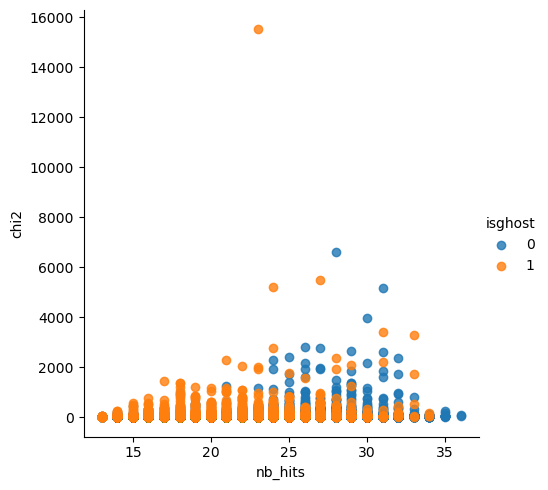

In [3]:
import seaborn as sns

sns.lmplot(x='nb_hits', y='chi2', hue='isghost', 
           data=df, 
           fit_reg=False)

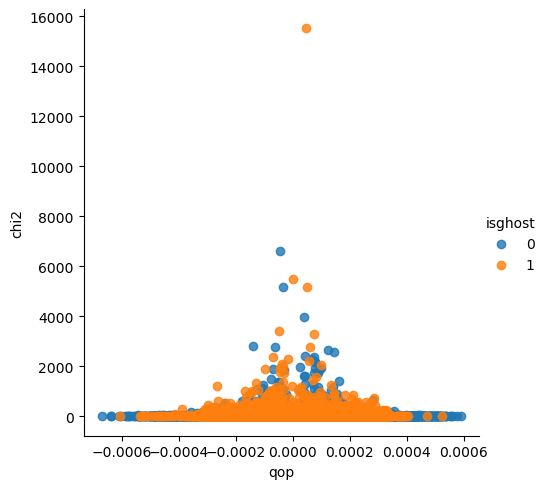

In [4]:
sns.lmplot(x='qop', y='chi2', hue='isghost', 
           data=df, 
           fit_reg=False)